TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

UPLOAD YOUR CIFAKE ZIP FILE


Saving archive (2).zip to archive (2) (2).zip
Uploaded: /content/archive (2) (2).zip
Dataset extracted.

TRAIN: /content/CIFAKE_DATASET/train
TEST : /content/CIFAKE_DATASET/test

TRAIN REAL: 50000
TRAIN FAKE: 50000
TEST REAL : 10000
TEST FAKE : 10000

Training: 9000
Validation: 1000
Testing: 20000
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MODEL READY
Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.6402 - loss: 0.6272
Epoch 1: val_accuracy improved from None to 0.83200, saving model to /content/CIFAKE_FINAL_RESULTS/models/best_model.keras

Epoch 1: finished saving model to /content/CIFAKE_FINAL_RESULTS/models/best_model.keras
282/282 ━━━━━━━━━━━━━━━━━━━━ 60s 117ms/step - accuracy: 0.7189 - loss: 0.5489 - val_accuracy: 0.8320 - val_loss: 0.4163 - learning_rate: 1.0000e-04
Epoch 2/5
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8193 - loss: 0.4139
Epoch 2: val_accuracy improved from 0.83200 to 0.85100, saving model to /content/CIFAKE_FINAL_RESULTS/mod

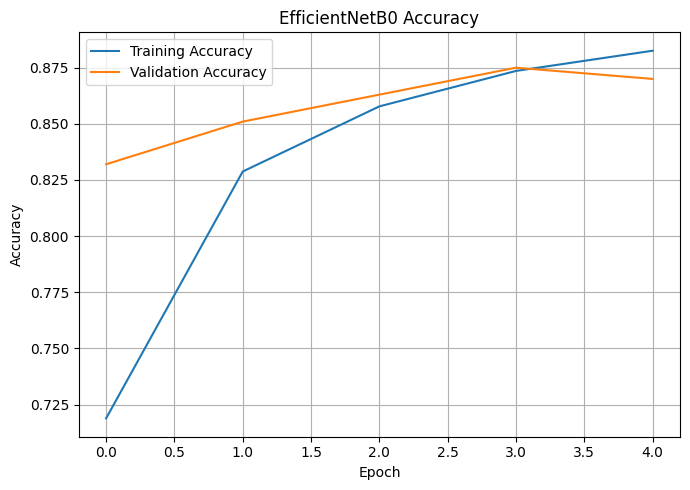

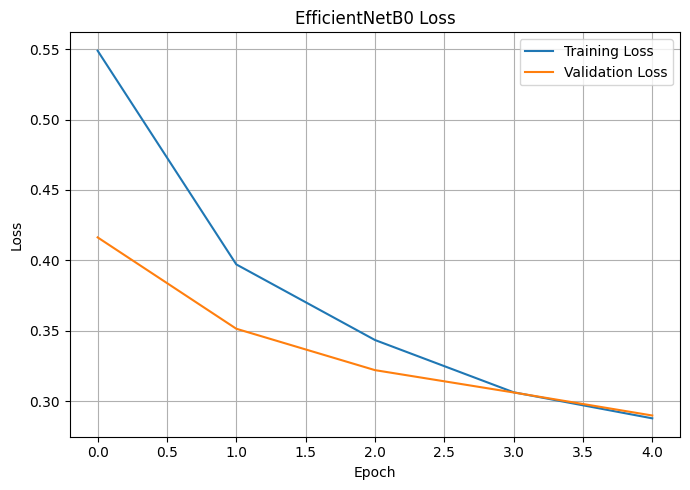

625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step


CIFAKE FINAL TEST RESULTS
Accuracy : 0.8774
Precision: 0.8876
Recall   : 0.8643
F1 Score : 0.8758
ROC-AUC  : 0.9496

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.87      0.89      0.88     10000
        REAL       0.89      0.86      0.88     10000

    accuracy                           0.88     20000
   macro avg       0.88      0.88      0.88     20000
weighted avg       0.88      0.88      0.88     20000



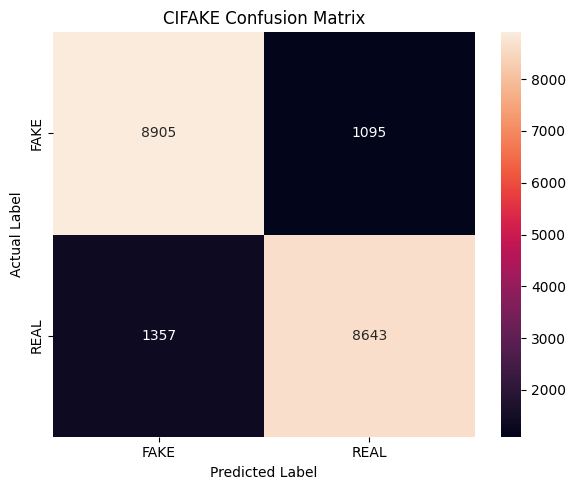

REAL IMAGE


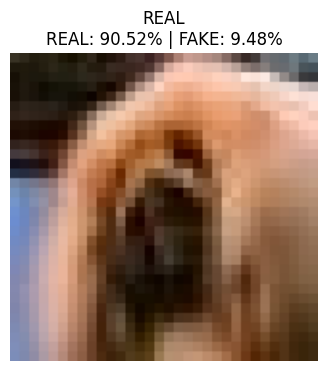

FAKE IMAGE


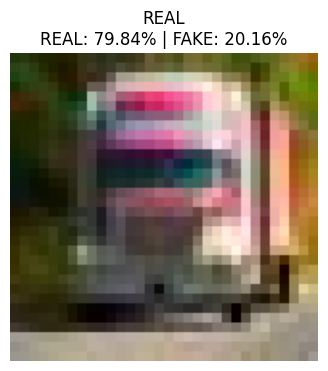

Grad-CAM layer: top_activation


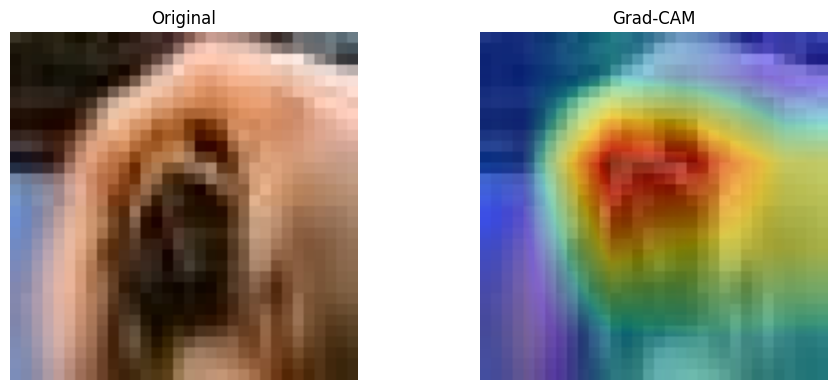


FINAL FILE CREATED:
/content/CIFAKE_FINAL.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ CIFAKE PROJECT PHASE 1 COMPLETE


In [ ]:
import os, random, zipfile, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

from google.colab import files



SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32


IMAGES_PER_CLASS = 5000


EPOCHS = 5

OUTPUT = "/content/CIFAKE_FINAL_RESULTS"

for folder in [
    OUTPUT,
    OUTPUT + "/models",
    OUTPUT + "/plots",
    OUTPUT + "/gradcam"
]:
    os.makedirs(folder, exist_ok=True)


print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))




print("\nUPLOAD YOUR CIFAKE ZIP FILE")

uploaded = files.upload()

zip_files = [
    x for x in uploaded
    if x.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "Please upload the CIFAKE dataset as a ZIP file."
    )

zip_path = "/content/" + zip_files[0]

print("Uploaded:", zip_path)




extract_path = "/content/CIFAKE_DATASET"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted.")



def find_folder(root, name):

    for current, dirs, files_ in os.walk(root):

        for d in dirs:

            if d.lower() == name.lower():

                return os.path.join(
                    current,
                    d
                )

    return None


TRAIN_DIR = find_folder(
    extract_path,
    "train"
)

TEST_DIR = find_folder(
    extract_path,
    "test"
)


print("\nTRAIN:", TRAIN_DIR)
print("TEST :", TEST_DIR)


if TRAIN_DIR is None or TEST_DIR is None:

    print("\nDataset structure found:")

    for root, dirs, files_ in os.walk(extract_path):

        level = root.replace(
            extract_path,
            ""
        ).count(os.sep)

        if level <= 3:

            print(
                "  " * level +
                os.path.basename(root) +
                "/"
            )

    raise FileNotFoundError(
        "TRAIN/TEST folders could not be found."
    )



def find_class(parent, name):

    for item in os.listdir(parent):

        path = os.path.join(
            parent,
            item
        )

        if (
            os.path.isdir(path)
            and item.lower() == name.lower()
        ):

            return path

    return None


def get_images(folder):

    extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp"
    )

    result = []

    for root, dirs, files_ in os.walk(folder):

        for f in files_:

            if f.lower().endswith(
                extensions
            ):

                result.append(
                    os.path.join(root, f)
                )

    return result


REAL_DIR = find_class(
    TRAIN_DIR,
    "REAL"
)

FAKE_DIR = find_class(
    TRAIN_DIR,
    "FAKE"
)

TEST_REAL_DIR = find_class(
    TEST_DIR,
    "REAL"
)

TEST_FAKE_DIR = find_class(
    TEST_DIR,
    "FAKE"
)


real_files = get_images(
    REAL_DIR
)

fake_files = get_images(
    FAKE_DIR
)

test_real_files = get_images(
    TEST_REAL_DIR
)

test_fake_files = get_images(
    TEST_FAKE_DIR
)


print("\nTRAIN REAL:", len(real_files))
print("TRAIN FAKE:", len(fake_files))

print("TEST REAL :", len(test_real_files))
print("TEST FAKE :", len(test_fake_files))



random.shuffle(real_files)
random.shuffle(fake_files)

n = min(
    IMAGES_PER_CLASS,
    len(real_files),
    len(fake_files)
)

real_files = real_files[:n]
fake_files = fake_files[:n]


data = []

for path in real_files:

    data.append(
        (path, 1)
    )


for path in fake_files:

    data.append(
        (path, 0)
    )


df = pd.DataFrame(
    data,
    columns=[
        "path",
        "label"
    ]
)


df = df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


train_df, val_df = train_test_split(
    df,
    test_size=0.10,
    stratify=df["label"],
    random_state=SEED
)


test_data = []

for path in test_real_files:

    test_data.append(
        (path, 1)
    )


for path in test_fake_files:

    test_data.append(
        (path, 0)
    )


test_df = pd.DataFrame(
    test_data,
    columns=[
        "path",
        "label"
    ]
)


test_df = test_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


print("\nTraining:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))



AUTO = tf.data.AUTOTUNE


def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape(
        [None, None, 3]
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )


    image = tf.cast(
        image,
        tf.float32
    )

    return (
        image,
        tf.cast(label, tf.float32)
    )


def make_dataset(
    dataframe,
    shuffle=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["path"].values,
            dataframe["label"].values
        )
    )

    if shuffle:

        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTO
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTO
    )

    return dataset


train_ds = make_dataset(
    train_df,
    True
)

val_ds = make_dataset(
    val_df
)

test_ds = make_dataset(
    test_df
)




base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128,128,3)
)

base_model.trainable = False


x = layers.GlobalAveragePooling2D()(
    base_model.output
)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(
    0.4
)(x)

output = layers.Dense(
    1,
    activation="sigmoid"
)(x)


model = Model(
    base_model.input,
    output
)


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


print("\nMODEL READY")




callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=1,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        OUTPUT + "/models/best_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]


start = time.time()


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


print(
    "\nTraining time:",
    round(
        (time.time() - start) / 60,
        2
    ),
    "minutes"
)



h = history.history


plt.figure(figsize=(7,5))

plt.plot(
    h["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    h["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNetB0 Accuracy"
)

plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig(
    OUTPUT + "/plots/accuracy.png",
    dpi=300
)

plt.show()


plt.figure(figsize=(7,5))

plt.plot(
    h["loss"],
    label="Training Loss"
)

plt.plot(
    h["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "EfficientNetB0 Loss"
)

plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig(
    OUTPUT + "/plots/loss.png",
    dpi=300
)

plt.show()



model = tf.keras.models.load_model(
    OUTPUT + "/models/best_model.keras"
)


probabilities = model.predict(
    test_ds,
    verbose=1
).ravel()


predictions = (
    probabilities >= 0.5
).astype(int)


true_labels = test_df["label"].values


accuracy = accuracy_score(
    true_labels,
    predictions
)

precision = precision_score(
    true_labels,
    predictions,
    zero_division=0
)

recall = recall_score(
    true_labels,
    predictions,
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predictions,
    zero_division=0
)

auc = roc_auc_score(
    true_labels,
    probabilities
)


print("\n")
print("=" * 50)
print("CIFAKE FINAL TEST RESULTS")
print("=" * 50)

print(
    "Accuracy :",
    round(accuracy, 4)
)

print(
    "Precision:",
    round(precision, 4)
)

print(
    "Recall   :",
    round(recall, 4)
)

print(
    "F1 Score :",
    round(f1, 4)
)

print(
    "ROC-AUC  :",
    round(auc, 4)
)


print("\nClassification Report:")

print(
    classification_report(
        true_labels,
        predictions,
        target_names=[
            "FAKE",
            "REAL"
        ],
        zero_division=0
    )
)


results = pd.DataFrame([
    {
        "Model": "EfficientNetB0",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    }
])


results.to_csv(
    OUTPUT + "/model_results.csv",
    index=False
)



cm = confusion_matrix(
    true_labels,
    predictions
)


plt.figure(
    figsize=(6,5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "FAKE",
        "REAL"
    ],
    yticklabels=[
        "FAKE",
        "REAL"
    ]
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.title(
    "CIFAKE Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    OUTPUT + "/plots/confusion_matrix.png",
    dpi=300
)

plt.show()




def predict_image(path):

    image = tf.keras.utils.load_img(
        path,
        target_size=IMG_SIZE
    )

    array = tf.keras.utils.img_to_array(
        image
    )

    array = np.expand_dims(
        array,
        axis=0
    )

    probability = float(
        model.predict(
            array,
            verbose=0
        )[0][0]
    )


    label = (
        "REAL"
        if probability >= 0.5
        else "FAKE"
    )


    plt.figure(
        figsize=(4,4)
    )

    plt.imshow(image)

    plt.title(
        f"{label}\n"
        f"REAL: {probability*100:.2f}% | "
        f"FAKE: {(1-probability)*100:.2f}%"
    )

    plt.axis("off")

    plt.show()


print("REAL IMAGE")
predict_image(
    test_real_files[0]
)


print("FAKE IMAGE")
predict_image(
    test_fake_files[0]
)



def find_last_4d_layer(model):

    for layer in reversed(
        model.layers
    ):

        try:

            if len(
                layer.output.shape
            ) == 4:

                return layer.name

        except:

            pass

    return None


layer_name = find_last_4d_layer(
    model
)


print(
    "Grad-CAM layer:",
    layer_name
)


grad_model = Model(
    model.inputs,
    [
        model.get_layer(
            layer_name
        ).output,
        model.output
    ]
)


path = test_real_files[0]


image = tf.keras.utils.load_img(
    path,
    target_size=IMG_SIZE
)

array = tf.keras.utils.img_to_array(
    image
)

input_image = tf.expand_dims(
    array,
    0
)


with tf.GradientTape() as tape:

    convolution_output, prediction = (
        grad_model(input_image)
    )

    score = prediction[:, 0]


gradients = tape.gradient(
    score,
    convolution_output
)


weights = tf.reduce_mean(
    gradients,
    axis=(1,2)
)


cam = tf.reduce_sum(
    convolution_output *
    weights[:,None,None,:],
    axis=-1
)[0]


cam = tf.maximum(
    cam,
    0
)


cam = cam / (
    tf.reduce_max(cam) + 1e-8
)


cam = tf.image.resize(
    cam[...,None],
    IMG_SIZE
).numpy().squeeze()


plt.figure(
    figsize=(10,4)
)


plt.subplot(1,2,1)

plt.imshow(image)

plt.title(
    "Original"
)

plt.axis("off")


plt.subplot(1,2,2)

plt.imshow(image)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    "Grad-CAM"
)

plt.axis("off")


plt.tight_layout()


plt.savefig(
    OUTPUT + "/gradcam/gradcam.png",
    dpi=300
)


plt.show()




zip_output = shutil.make_archive(
    "/content/CIFAKE_FINAL",
    "zip",
    OUTPUT
)


print(
    "\nFINAL FILE CREATED:"
)

print(
    zip_output
)


files.download(
    zip_output
)


print(
    "\n✅ CIFAKE PROJECT PHASE 1 COMPLETE"
)

In [ ]:
import os

model_path = "/content/CIFAKE_FINAL_RESULTS/models/best_model.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path)/(1024*1024), 2),
        "MB"
    )

Model exists: False


In [ ]:
import os

base = "/content/CIFAKE_FINAL_RESULTS"

for root, dirs, files_ in os.walk(base):

    level = root.replace(base, "").count(os.sep)

    print("  " * level + os.path.basename(root) + "/")

    for f in files_:
        path = os.path.join(root, f)
        size = os.path.getsize(path)/(1024*1024)

        print(
            "  " * (level+1),
            f,
            f"({size:.2f} MB)"
        )

In [ ]:
import os

print("Folders/files inside /content:\n")

for item in os.listdir("/content"):
    print(item)

Folders/files inside /content:

.config
sample_data


In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/content"):
    if "model_results.csv" in files or "best_model.keras" in files:
        matches.append(root)

print("Possible result folders:")
for m in matches:
    print(m)

Possible result folders:


In [ ]:
import os

print("Inside sample_data:")

for root, dirs, files in os.walk("/content/sample_data"):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)

Inside sample_data:

Folder: /content/sample_data
   anscombe.json
   README.md
   mnist_train_small.csv
   california_housing_test.csv
   mnist_test.csv
   california_housing_train.csv


In [ ]:
import shutil
import os

zip_path = shutil.make_archive(
    "/content/sample_data_backup",
    "zip",
    "/content/sample_data"
)

print("ZIP CREATED:")
print(zip_path)

print(
    "ZIP size:",
    round(os.path.getsize(zip_path) / (1024 * 1024), 2),
    "MB"
)

ZIP CREATED:
/content/sample_data_backup.zip
ZIP size: 6.74 MB


In [ ]:
from google.colab import files

files.download(
    "/content/sample_data_backup.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>